In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
DATA_PATH = Path("../data/processed/employee_attrition_cleaned.csv")

df = pd.read_csv(DATA_PATH)


# Separate features and target
X = df.drop(columns=["Attrition"])
y = df["Attrition"].map({"No": 0, "Yes": 1})

# First split: 80% development data, 20% final test data
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 75% training, 25% validation from development data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Training set: (882, 30)
Validation set: (294, 30)
Test set: (294, 30)


In [3]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)


Training: (882, 51)
Validation: (294, 51)
Test: (294, 51)


In [4]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=8, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        max_depth=12, min_samples_split=5,
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05,
        max_depth=3, random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.8741,0.6316,0.5106,0.5647,0.8021
0,Logistic Regression,0.7483,0.3579,0.7234,0.4789,0.8175
3,Gradient Boosting,0.8673,0.7222,0.2766,0.4000,0.7858
1,Decision Tree,0.7585,0.3235,0.4681,0.3826,0.6344


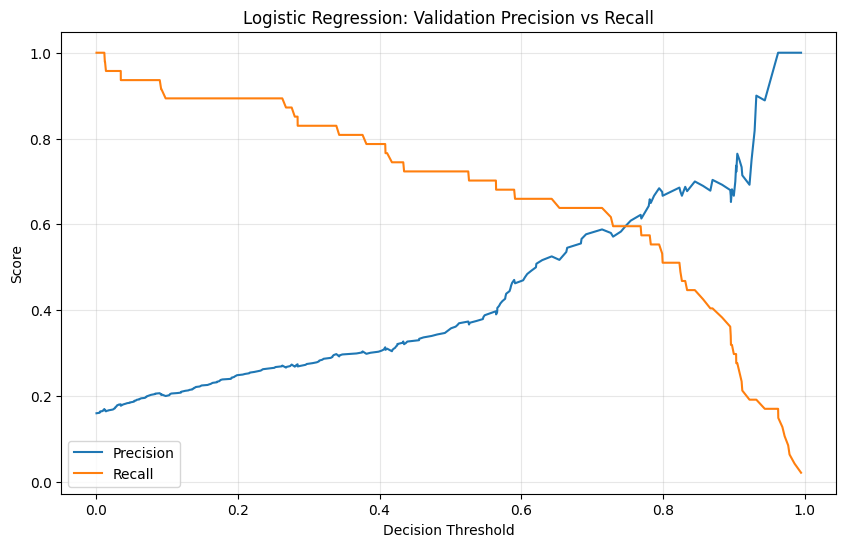

--- WRITTEN SUMMARY FOR YOUR REPORT ---
Figure Summary: The chart illustrates the precision-recall trade-off for the Logistic Regression model across decision thresholds ranging from 0.00 to 0.99.
• Balanced Trade-Off: Precision and recall intersect at a threshold of 0.75, achieving a balanced score of 0.60 for both metrics.
• Default Threshold (0.50): At the standard 0.50 cutoff, the model yields a precision of 0.36 and a recall of 0.72.
• Trend: Lowering the threshold below 0.75 prioritizes catching more positive cases (higher recall), while raising it reduces false positives (higher precision).


In [5]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

# Get validation probabilities
logistic_model = trained_models["Logistic Regression"]
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

# Plot the trade-off
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Validation Precision vs Recall")
plt.legend()
plt.grid(alpha=0.3)

# 1. Save high-resolution image for Word, Docs, or PDF
plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Generate a written summary of the graph
# Find the balance point where Precision and Recall are closest
diff = np.abs(precision[:-1] - recall[:-1])
best_idx = np.argmin(diff)
bal_thresh = thresholds[best_idx]
bal_score = precision[best_idx]

# Find scores at the default 0.50 threshold
default_idx = np.argmin(np.abs(thresholds - 0.50))

print("--- WRITTEN SUMMARY FOR YOUR REPORT ---")
print(f"Figure Summary: The chart illustrates the precision-recall trade-off for the Logistic Regression model across decision thresholds ranging from {thresholds.min():.2f} to {thresholds.max():.2f}.")
print(f"• Balanced Trade-Off: Precision and recall intersect at a threshold of {bal_thresh:.2f}, achieving a balanced score of {bal_score:.2f} for both metrics.")
print(f"• Default Threshold (0.50): At the standard 0.50 cutoff, the model yields a precision of {precision[default_idx]:.2f} and a recall of {recall[default_idx]:.2f}.")
print(f"• Trend: Lowering the threshold below {bal_thresh:.2f} prioritizes catching more positive cases (higher recall), while raising it reduces false positives (higher precision).")


In [6]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Candidate threshold
selected_threshold = 0.75

# Validation predictions using custom threshold
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]
y_val_pred = (y_val_prob >= selected_threshold).astype(int)

# Evaluation
print("Threshold:", selected_threshold)
print("\nClassification Report:")
print(classification_report(
    y_val, y_val_pred,
    target_names=["No Attrition", "Attrition"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1 Score:", f1_score(y_val, y_val_pred))


Threshold: 0.75

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.92      0.93      0.93       247
   Attrition       0.61      0.60      0.60        47

    accuracy                           0.87       294
   macro avg       0.77      0.76      0.76       294
weighted avg       0.87      0.87      0.87       294

Confusion Matrix:
[[229  18]
 [ 19  28]]
Accuracy: 0.8741496598639455
Precision: 0.6086956521739131
Recall: 0.5957446808510638
F1 Score: 0.6021505376344086


In [7]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Keep the selected threshold fixed
selected_threshold = 0.75

# Predict probabilities on the untouched test set
y_test_prob = logistic_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

# Final evaluation
print("Final Test Evaluation")
print("Threshold:", selected_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Attrition", "Attrition"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nPerformance Metrics:")
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_test_prob))


Final Test Evaluation
Threshold: 0.75

Classification Report:
              precision    recall  f1-score   support

No Attrition       0.90      0.92      0.91       247
   Attrition       0.54      0.47      0.50        47

    accuracy                           0.85       294
   macro avg       0.72      0.70      0.71       294
weighted avg       0.84      0.85      0.85       294

Confusion Matrix:
[[228  19]
 [ 25  22]]

Performance Metrics:
Accuracy: 0.8503401360544217
Precision: 0.5365853658536586
Recall: 0.46808510638297873
F1 Score: 0.5
ROC AUC: 0.78223791885606


In [8]:

import pandas as pd
import numpy as np

# Extract fitted preprocessing and Logistic Regression
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]

# Get encoded feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract model coefficients
coefficients = classifier.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print("Top 15 Influential Features:")
display(feature_importance.head(15).round(4))


Top 15 Influential Features:


,Feature,Coefficient,Absolute Importance
39,cat__JobRole_Laboratory Technician,1.1672,1.1672
42,cat__JobRole_Research Director,-1.1301,1.1301
45,cat__JobRole_Sales Representative,1.0156,1.0156
23,cat__BusinessTravel_Non-Travel,-0.9460,0.9460
49,cat__OverTime_No,-0.9369,0.9369
24,cat__BusinessTravel_Travel_Frequently,0.8685,0.8685
50,cat__OverTime_Yes,0.8441,0.8441
16,num__TotalWorkingYears,-0.8282,0.8282
7,num__JobLevel,0.6912,0.6912
29,cat__EducationField_Human Resources,0.6857,0.6857


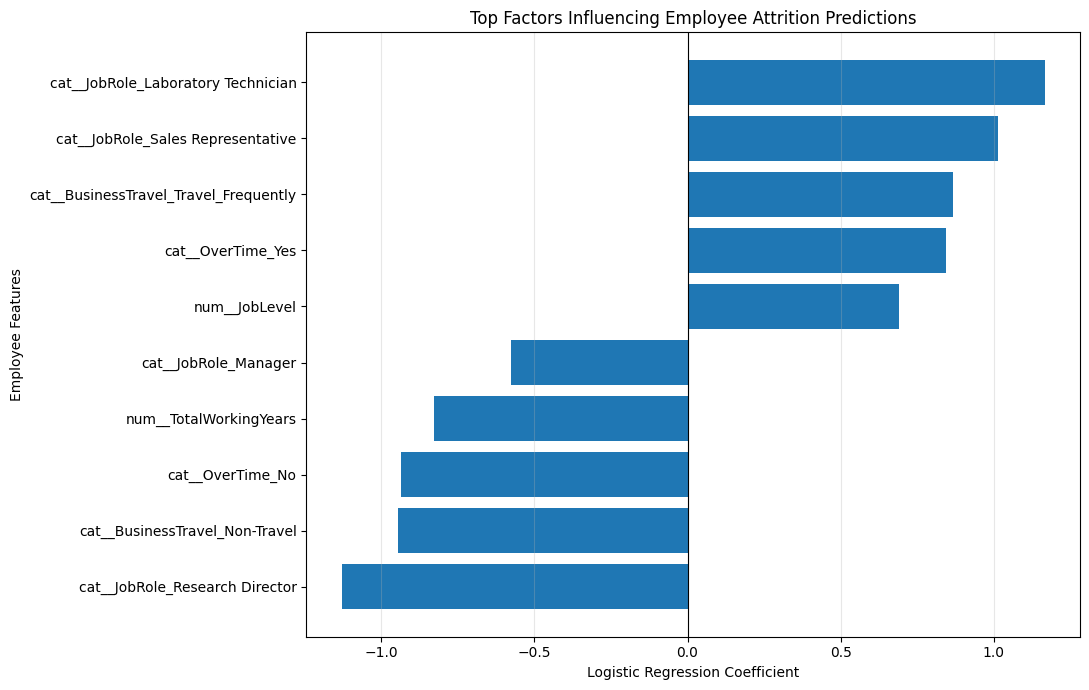

--- WRITTEN SUMMARY FOR YOUR REPORT ---
Figure Summary: This horizontal bar chart highlights the top 10 employee features driving the Logistic Regression model's attrition predictions.
• Strongest Drivers of Attrition (Positive Coefficients): cat__JobRole_Laboratory Technician (1.17), cat__JobRole_Sales Representative (1.02), cat__BusinessTravel_Travel_Frequently (0.87), cat__OverTime_Yes (0.84), num__JobLevel (0.69). Higher values in these areas increase the predicted likelihood of an employee leaving.
• Strongest Retention Factors (Negative Coefficients): cat__JobRole_Research Director (-1.13), cat__BusinessTravel_Non-Travel (-0.95), cat__OverTime_No (-0.94), num__TotalWorkingYears (-0.83), cat__JobRole_Manager (-0.58). Higher values in these areas reduce the predicted risk of attrition.
• Key Takeaway: 'cat__JobRole_Laboratory Technician' has the single largest upward impact on attrition risk, whereas 'cat__JobRole_Research Director' provides the strongest protective effect against 

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Select five strongest positive and negative coefficients
top_positive = feature_importance.nlargest(5, "Coefficient")
top_negative = feature_importance.nsmallest(5, "Coefficient")

plot_data = pd.concat([top_negative, top_positive])
plot_data = plot_data.sort_values("Coefficient")

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Employee Features")
plt.title("Top Factors Influencing Employee Attrition Predictions")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 1. Save high-resolution image for Word, Docs, or PDF
plt.savefig("attrition_top_factors.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Generate a written summary of the graph
# Sort top features from strongest to weakest impact
pos_sorted = top_positive.sort_values("Coefficient", ascending=False)
neg_sorted = top_negative.sort_values("Coefficient", ascending=True)

top_pos_list = [f"{row['Feature']} ({row['Coefficient']:.2f})" for _, row in pos_sorted.iterrows()]
top_neg_list = [f"{row['Feature']} ({row['Coefficient']:.2f})" for _, row in neg_sorted.iterrows()]

print("--- WRITTEN SUMMARY FOR YOUR REPORT ---")
print("Figure Summary: This horizontal bar chart highlights the top 10 employee features driving the Logistic Regression model's attrition predictions.")
print(f"• Strongest Drivers of Attrition (Positive Coefficients): {', '.join(top_pos_list)}. Higher values in these areas increase the predicted likelihood of an employee leaving.")
print(f"• Strongest Retention Factors (Negative Coefficients): {', '.join(top_neg_list)}. Higher values in these areas reduce the predicted risk of attrition.")
print(f"• Key Takeaway: '{pos_sorted.iloc[0]['Feature']}' has the single largest upward impact on attrition risk, whereas '{neg_sorted.iloc[0]['Feature']}' provides the strongest protective effect against turnover.")


In [10]:

import joblib
from pathlib import Path

# Create models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save complete Logistic Regression pipeline
model_path = models_dir / "employee_attrition_model.joblib"

joblib.dump(
    {
        "model": logistic_model,
        "threshold": selected_threshold
    },
    model_path
)

print("Model and threshold saved successfully!")
print("Location:", model_path.resolve())
print("Selected threshold:", selected_threshold)


Model and threshold saved successfully!
Location: C:\Users\Tanish_Gupta\OneDrive\Desktop\ProdIntel\models\employee_attrition_model.joblib
Selected threshold: 0.75


In [11]:
import sys
import sklearn

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Executable:", sys.executable)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Scikit-learn: 1.9.1
Executable: c:\Users\Tanish_Gupta\OneDrive\Desktop\ProdIntel\.venv312\Scripts\python.exe


In [12]:
import sys
import sklearn

print("Python:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: c:\Users\Tanish_Gupta\OneDrive\Desktop\ProdIntel\.venv312\Scripts\python.exe
Scikit-learn: 1.9.1
